# SwiftMove Logistics — Delivery Operations Analysis

## 1. Business Overview

SwiftMove Logistics is a Lagos-based delivery company operating across **Lagos Island, Victoria Island, Lekki, and Ikeja**.

The company handles daily delivery requests from customers across these locations. However, management has recently noticed some operational challenges:

- Delivery requests fluctuate throughout the day.
- Customers complain about unpredictable delivery times.
- Some deliveries take significantly longer than expected, affecting customer satisfaction.

Management wants to better understand these uncertainties before making decisions about expanding its delivery workforce.

## 2. Business Problem

SwiftMove Logistics needs a data-driven approach to understanding its delivery demand and operational risks.

Currently, the company does not have a clear understanding of how many delivery requests to expect within a given hour or how likely deliveries are to exceed their expected completion time.

As a Data Analyst, my responsibility is to investigate these uncertainties using **Probability Distributions** and statistical analysis.

The central business question is:

> Can probability distributions help SwiftMove Logistics understand its delivery demand, predict delivery delays, and determine how many operational resources it should prepare for?

### Key Business Questions

1. **Delivery Demand:** How many delivery requests should the company expect per hour?
2. **Delivery Delays:** What is the probability that a delivery exceeds 60 minutes?
3. **Operational Decisions:** What resource allocation and operational decisions can management make from these probabilities?

### Install and import libraries

In [2]:
# Import required libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import poisson, expon, norm

# Ensure reproducible results
np.random.seed(42)

### Define business assumptions

In [3]:
# Expected average number of delivery requests received per hour
AVERAGE_REQUESTS = 12

# Expected average time required to complete a delivery (minutes)
AVERAGE_DELIVERY_TIME = 40

# Standard deviation of delivery duration (minutes)
# Represents the expected variability around the average delivery time
DELIVERY_STD = 10

# Maximum acceptable delivery duration before a delivery is classified as delayed (minutes)
DELAY_THRESHOLD = 60

# Number of days to simulate for the operational analysis
SIMULATION_DAYS = 30

# Number of operating hours assumed per day
HOURS_PER_DAY = 24

### Simulate delivery demand — Poisson distribution


**Business question: How many delivery requests should SwiftMove expect per hour?**

-**We assume an average of 12 requests per hour**-

In [4]:
# Simulate hourly delivery requests for 30 days

total_hours = SIMULATION_DAYS * HOURS_PER_DAY

hourly_requests = poisson.rvs(
    mu=AVERAGE_REQUESTS,
    size=total_hours
)

# Calculate total demand

total_requests = hourly_requests.sum()

average_hourly_demand = hourly_requests.mean()

print("TOTAL DELIVERY REQUESTS:", total_requests)

print("AVERAGE HOURLY DEMAND:", round(average_hourly_demand, 2))

TOTAL DELIVERY REQUESTS: 8588
AVERAGE HOURLY DEMAND: 11.93


### Simulate Waiting Times — Exponential Distribution

**Business question:** How long should SwiftMove expect to wait between incoming delivery requests?

Remember:

Average waiting time = $\frac{60}{12} = 5$ minutes.

Therefore, the average waiting time is **five minutes**.

In [5]:
# Simulate time between incoming requests

waiting_times = expon.rvs(
    scale=60 / AVERAGE_REQUESTS,
    size=total_requests
)

average_waiting = waiting_times.mean()

print("AVERAGE WAITING TIME:",
      round(average_waiting, 2), "minutes")

AVERAGE WAITING TIME: 4.86 minutes


### Simulate Delivery Completion Times — Normal Distribution

**Business question:** How long does SwiftMove typically take to complete a delivery?

Our assumptions:

- Mean delivery time = 40 minutes.
- Standard deviation = 10 minutes.

In [6]:
# Simulate delivery completion times

delivery_times = norm.rvs(
    loc=AVERAGE_DELIVERY_TIME,
    scale=DELIVERY_STD,
    size=total_requests
)

# Remove physically impossible negative durations
delivery_times = np.clip(delivery_times, 0, None)

average_delivery = delivery_times.mean()

print("AVERAGE DELIVERY TIME:",
      round(average_delivery, 2), "minutes")

AVERAGE DELIVERY TIME: 40.09 minutes


### Calculate Operational Risk

In [7]:
# Probability of a delivery exceeding 60 minutes

delay_probability = 1 - norm.cdf(
    DELAY_THRESHOLD,
    loc=AVERAGE_DELIVERY_TIME,
    scale=DELIVERY_STD
)

# Convert probability to percentage

delay_percentage = delay_probability * 100

# Expected number of delayed deliveries
# Based on the modelled probability

expected_delays = total_requests * delay_probability

print("\nDELIVERY RISK ANALYSIS")

print("Probability of delay:",
      round(delay_percentage, 2), "%")

print("Expected delayed deliveries:",
      round(expected_delays, 2))


DELIVERY RISK ANALYSIS
Probability of delay: 2.28 %
Expected delayed deliveries: 195.38


The theoretical probability is approximately 2.28%.

That means that, under our assumed normal model, approximately 2.28 out of every 100 deliveries could exceed 60 minutes.

### Calculate additional demand probabilities
Let's also determine the probability of receiving more than 15 requests in an hour

In [8]:
# Probability of receiving more than 15 requests

high_demand_probability = 1 - poisson.cdf(
    15,
    mu=AVERAGE_REQUESTS
)

print("\nDEMAND RISK ANALYSIS")

print("Probability of exceeding 15 requests:",
      round(high_demand_probability * 100, 2), "%")


DEMAND RISK ANALYSIS
Probability of exceeding 15 requests: 15.56 %


### Generate visualisations
Let's visualise the three distributions.

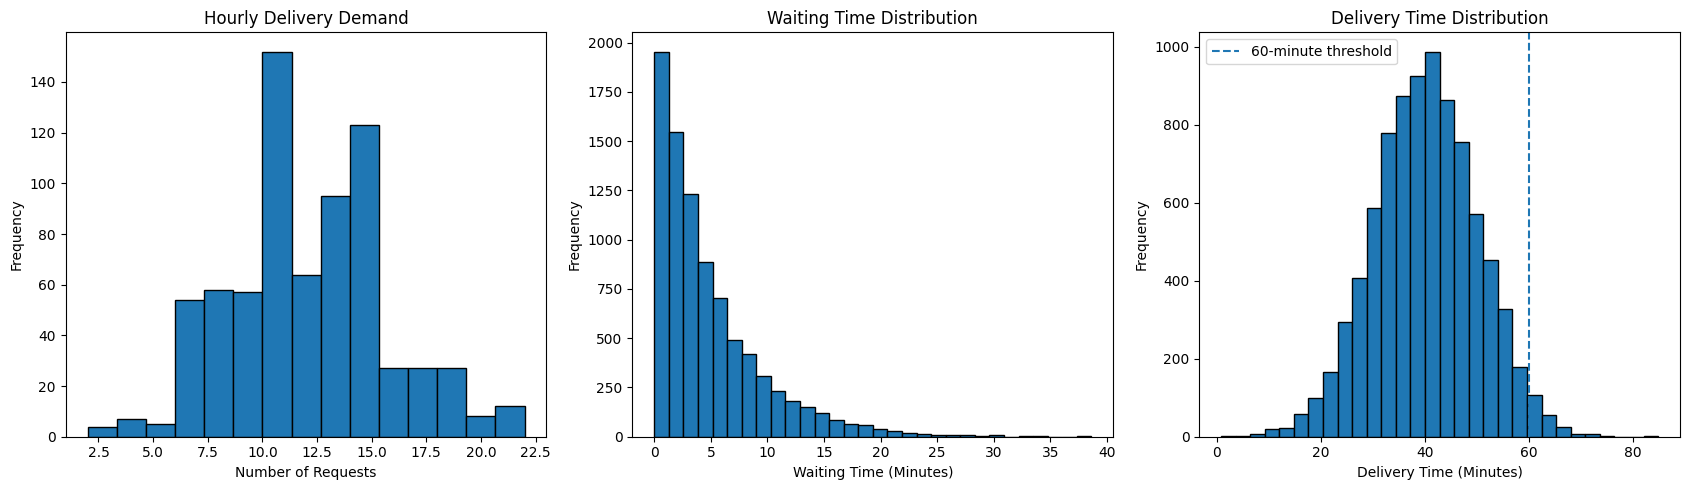

In [9]:
# Create three distribution plots

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

# Chart 1: Hourly demand
axes[0].hist(hourly_requests, bins=15, edgecolor="black")
axes[0].set_title("Hourly Delivery Demand")
axes[0].set_xlabel("Number of Requests")
axes[0].set_ylabel("Frequency")

# Chart 2: Waiting times
axes[1].hist(waiting_times, bins=30, edgecolor="black")
axes[1].set_title("Waiting Time Distribution")
axes[1].set_xlabel("Waiting Time (Minutes)")
axes[1].set_ylabel("Frequency")

# Chart 3: Delivery completion times
axes[2].hist(delivery_times, bins=30, edgecolor="black")
axes[2].axvline(
    DELAY_THRESHOLD,
    linestyle="--",
    label="60-minute threshold"
)
axes[2].set_title("Delivery Time Distribution")
axes[2].set_xlabel("Delivery Time (Minutes)")
axes[2].set_ylabel("Frequency")
axes[2].legend()

plt.tight_layout()
plt.show()

# Export the results
Save our simulated data so that the company can inspect it later.

In [10]:
# Create a dataframe containing operational observations

operations = pd.DataFrame({
    "hourly_requests": hourly_requests
})

operations.to_csv(
    "data/hourly_demand.csv",
    index=False
)

# Save delivery and waiting time observations separately

pd.DataFrame({
    "waiting_time_minutes": waiting_times
}).to_csv("data/waiting_times.csv", index=False)

pd.DataFrame({
    "delivery_time_minutes": delivery_times
}).to_csv("data/delivery_times.csv", index=False)

print("\nSimulation data exported successfully.")


Simulation data exported successfully.


## Business Insights & Recommendations

In [11]:
# ==========================================
# BUSINESS PERFORMANCE REPORT
# ==========================================

print("\n")
print("=" * 45)
print("SWIFTMOVE LOGISTICS")
print("30-DAY OPERATIONS ANALYTICS REPORT")
print("=" * 45)

print(f"Total delivery requests: {total_requests}")

print(f"Average hourly demand: "
      f"{average_hourly_demand:.2f}")

print(f"Average waiting time: "
      f"{average_waiting:.2f} minutes")

print(f"Average delivery time: "
      f"{average_delivery:.2f} minutes")

print(f"Probability of high demand: "
      f"{high_demand_probability * 100:.2f}%")

print(f"Probability of delivery delay: "
      f"{delay_percentage:.2f}%")

print(f"Expected delayed deliveries: "
      f"{expected_delays:.2f}")

print("=" * 45)



SWIFTMOVE LOGISTICS
30-DAY OPERATIONS ANALYTICS REPORT
Total delivery requests: 8588
Average hourly demand: 11.93
Average waiting time: 4.86 minutes
Average delivery time: 40.09 minutes
Probability of high demand: 15.56%
Probability of delivery delay: 2.28%
Expected delayed deliveries: 195.38


## 3. Business Recommendations & Operational Strategy

Based on the probability analysis, I recommend that SwiftMove Logistics adopt the following operational strategies:

### 1. Improve Rider Capacity Planning
With an average demand of 12 requests per hour, management should use hourly demand patterns to guide rider scheduling. Additional rider capacity should be made available during periods of unusually high demand.

### 2. Strengthen Dispatch Operations
Since incoming requests are unpredictable, dispatchers should be prepared for closely spaced delivery requests. An efficient request allocation system will help prevent rider overload and reduce waiting times.

### 3. Introduce Delivery Delay Monitoring
The estimated 2.28% probability of deliveries exceeding 60 minutes provides an initial service-risk benchmark. I recommend implementing a monitoring system that flags deliveries approaching the 60-minute threshold, allowing dispatchers to intervene early.

### 4. Validate and Improve the Model
These findings are based on theoretical assumptions and simulated data. SwiftMove should begin collecting actual delivery records to validate the models, identify operational bottlenecks, and improve prediction accuracy over time.

### Final Professional Recommendation

I recommend that SwiftMove prioritise **data-driven rider scheduling, proactive delay monitoring, and continuous operational performance tracking** before committing to major workforce expansion.

The current analysis provides a useful foundation for understanding operational uncertainty. However, determining the exact number of riders required will require additional information about rider availability, delivery locations, working hours, and delivery capacity.

**The objective should not simply be to employ more riders, but to ensure that the right number of riders is available at the right time and in the right locations.**